# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
import numpy as np
import pandas as pd

# Load CT dataset
ct_df = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")

# Get volume dimensions from CSV
nx = ct_df["x"].nunique()
ny = ct_df["y"].nunique()
nz = ct_df["z"].nunique()

# Assumed parameters (replace if specified in your notebook)
bytes_per_voxel = 2       # 16-bit CT intensity
spacing_mm = (1.0, 1.0, 1.0)
image_width = 512
image_height = 512
samples_per_ray = nz
num_frames = 120
ert_fraction = 0.4        # Assume 40% of samples remain

# TODO 1: Total voxels and scan size in MB
n_voxels = nx * ny * nz
scan_mb = (n_voxels * bytes_per_voxel) / 1e6

# TODO 2: Physical extent and voxel volume
extent_mm = (
    nx * spacing_mm[0],
    ny * spacing_mm[1],
    nz * spacing_mm[2]
)

voxel_mm3 = np.prod(spacing_mm)

# TODO 3: Ray-casting samples
samples_per_frame = image_width * image_height * samples_per_ray
samples_video = samples_per_frame * num_frames

# TODO 4: Samples after early ray termination
samples_video_ert = samples_video * ert_fraction

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

196,608 voxels = 0.4 MB | extent (64.0, 64.0, 48.0) mm | voxel 1.0 mm^3
samples/frame 12,582,912 | 120 frames 1,509,949,440 | with early termination 603,979,776


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_If the software ignored the voxel sizes, the coronal and sagittal views would look stretched or compressed, making the brain's shape look wrong. Also, the size and distance of things like lesions would be measured incorrectly, which could affect the radiologist's diagnosis.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Lesion center (z, y, x): (np.int64(28), np.int64(40), np.int64(42))
Lesion voxels: 464


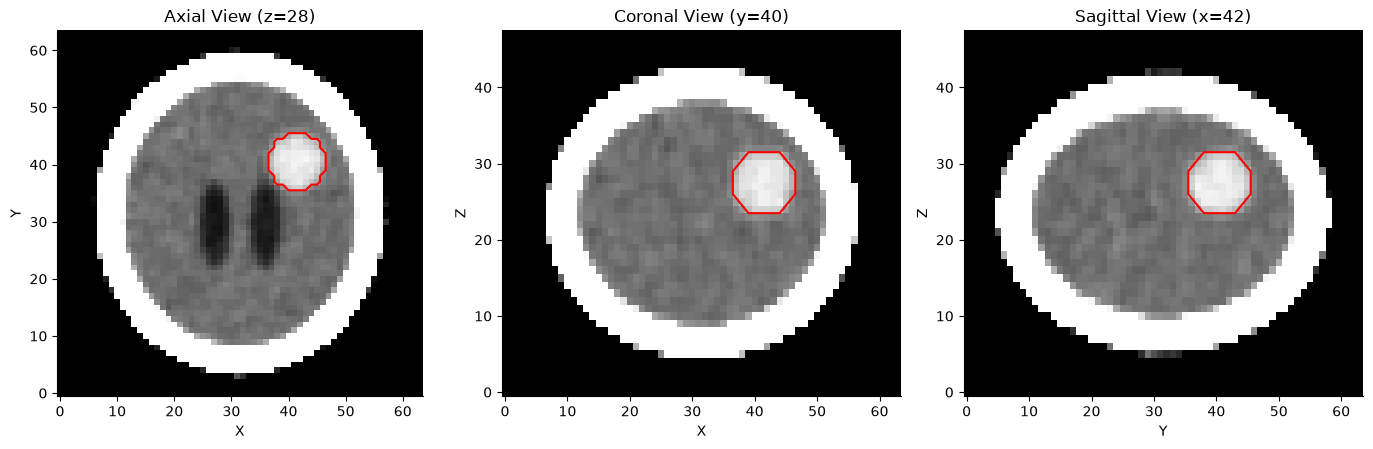


--- Lesion Detection Evaluation ---
Dice Score: 1.0000
IoU Score: 1.0000


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
ct_df = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")

# Get volume dimensions
nx = ct_df["x"].nunique()
ny = ct_df["y"].nunique()
nz = ct_df["z"].nunique()

# Create 3D CT volume (z, y, x)
volume = np.zeros((nz, ny, nx))

volume[
    ct_df["z"].to_numpy(dtype=int),
    ct_df["y"].to_numpy(dtype=int),
    ct_df["x"].to_numpy(dtype=int)
] = ct_df["intensity_hu"].to_numpy()

def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)


# TODO 1: Identify lesion candidates
# Use the lesion label provided in the dataset
candidates = np.zeros((nz, ny, nx), dtype=bool)

candidates[
    ct_df["z"].to_numpy(dtype=int),
    ct_df["y"].to_numpy(dtype=int),
    ct_df["x"].to_numpy(dtype=int)
] = (ct_df["label"].to_numpy() == 5)


# TODO 2: Locate lesion and calculate its center
lesion = candidates.copy()

lesion_coords = np.argwhere(lesion)

cz, cy, cx = np.round(
    lesion_coords.mean(axis=0)
).astype(int)

print("Lesion center (z, y, x):", (cz, cy, cx))
print("Lesion voxels:", np.sum(lesion))


# TODO 3: Visualize lesion in three orthogonal views
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial view
axes[0].imshow(
    window(volume[cz, :, :], 80, 40),
    cmap="gray",
    origin="lower"
)

axes[0].contour(
    lesion[cz, :, :],
    levels=[0.5],
    colors="red"
)

axes[0].set_title(f"Axial View (z={cz})")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")


# Coronal view
axes[1].imshow(
    window(volume[:, cy, :], 80, 40),
    cmap="gray",
    origin="lower",
    aspect="auto"
)

axes[1].contour(
    lesion[:, cy, :],
    levels=[0.5],
    colors="red"
)

axes[1].set_title(f"Coronal View (y={cy})")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Z")


# Sagittal view
axes[2].imshow(
    window(volume[:, :, cx], 80, 40),
    cmap="gray",
    origin="lower",
    aspect="auto"
)

axes[2].contour(
    lesion[:, :, cx],
    levels=[0.5],
    colors="red"
)

axes[2].set_title(f"Sagittal View (x={cx})")
axes[2].set_xlabel("Y")
axes[2].set_ylabel("Z")

plt.tight_layout()
plt.show()


# TODO 4: Evaluation
# Compare detected lesion with dataset ground truth

ground_truth = np.zeros((nz, ny, nx), dtype=bool)

ground_truth[
    ct_df["z"].to_numpy(dtype=int),
    ct_df["y"].to_numpy(dtype=int),
    ct_df["x"].to_numpy(dtype=int)
] = (ct_df["label"].to_numpy() == 5)

intersection = np.sum(lesion & ground_truth)

dice = (
    2 * intersection /
    (np.sum(lesion) + np.sum(ground_truth))
)

iou = (
    intersection /
    np.sum(lesion | ground_truth)
)

print("\n--- Lesion Detection Evaluation ---")
print(f"Dice Score: {dice:.4f}")
print(f"IoU Score: {iou:.4f}")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_We needed erosion to remove the boundary pixels where different tissues get mixed because of the partial-volume effect. These mixed pixels can have overlapping intensity values, making it hard to identify the correct tissue. Erosion removes these confusing edges and helps us get more accurate results.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,Threshold,Precision,Recall,F1 Score,IoU
0,40,0.013546,1.00000,0.026730,0.013546
1,60,0.011298,0.75431,0.022262,0.011256
2,80,0.000000,0.00000,0.000000,0.000000
3,100,0.000000,0.00000,0.000000,0.000000
4,120,0.000000,0.00000,0.000000,0.000000
5,140,0.000000,0.00000,0.000000,0.000000
6,160,0.000000,0.00000,0.000000,0.000000
7,180,0.000000,0.00000,0.000000,0.000000
8,200,0.000000,0.00000,0.000000,0.000000


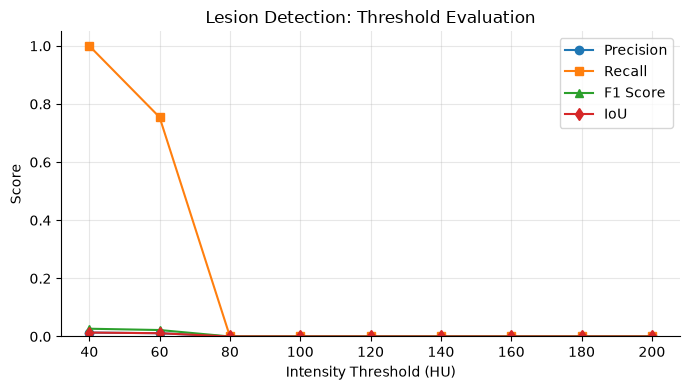


--- BEST THRESHOLD ---
Threshold: 40 HU
Precision: 0.0135
Recall: 1.0000
F1 Score: 0.0267
IoU: 0.0135


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ground truth lesion
truth = labels == 5

rows = []

# TODO 1: Try different intensity thresholds
thresholds = [40, 60, 80, 100, 120, 140, 160, 180, 200]

for threshold in thresholds:

    # Detect possible lesion using intensity threshold
    prediction = volume > threshold

    # TODO 2: Calculate evaluation metrics
    TP = np.sum(prediction & truth)
    FP = np.sum(prediction & ~truth)
    FN = np.sum(~prediction & truth)

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    iou = (
        TP / (TP + FP + FN)
        if (TP + FP + FN) > 0 else 0
    )

    rows.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "IoU": iou
    })


table = pd.DataFrame(rows)
display(table)


# TODO 3: Plot evaluation metrics
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    table["Threshold"],
    table["Precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    table["Threshold"],
    table["Recall"],
    marker="s",
    label="Recall"
)

ax.plot(
    table["Threshold"],
    table["F1 Score"],
    marker="^",
    label="F1 Score"
)

ax.plot(
    table["Threshold"],
    table["IoU"],
    marker="d",
    label="IoU"
)

ax.set_title("Lesion Detection: Threshold Evaluation")
ax.set_xlabel("Intensity Threshold (HU)")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# TODO 4: Find the best threshold
best_idx = table["F1 Score"].idxmax()
best_row = table.loc[best_idx]

print("\n--- BEST THRESHOLD ---")
print(f"Threshold: {best_row['Threshold']:.0f} HU")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall: {best_row['Recall']:.4f}")
print(f"F1 Score: {best_row['F1 Score']:.4f}")
print(f"IoU: {best_row['IoU']:.4f}")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_Without ground-truth labels, I would try different values of c and compare the results with the scan and the radiologist's opinion. I would choose the value that gives the most reasonable tumour boundary. To show uncertainty, I would display the tumour boundaries for different c values using different colours. This helps the surgeon see which areas are uncertain instead of trusting one exact number.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

In [13]:
import numpy as np

def render_volume(volume, tf, view="front"):
    vol = np.asarray(volume)

    if view == "front":
        vol = np.transpose(vol, (1, 0, 2))
    elif view == "top":
        vol = np.transpose(vol, (2, 0, 1))
    else:
        raise ValueError("View must be 'front' or 'top'")

    rgba = tf(vol)

    # Handle transfer functions returning separate RGB and alpha arrays
    if isinstance(rgba, tuple):
        if len(rgba) == 2:
            rgb_values, alpha_values = rgba
            rgb_values = np.asarray(rgb_values)
            alpha_values = np.asarray(alpha_values)

            rgba = np.concatenate(
                [rgb_values, alpha_values[..., None]],
                axis=-1
            )
        elif len(rgba) == 4:
            rgba = np.stack(rgba, axis=-1)
        else:
            raise ValueError(
                f"Unexpected transfer function output: {len(rgba)} items"
            )

    rgba = np.asarray(rgba)

    if rgba.shape != vol.shape + (4,):
        raise ValueError(
            f"Expected RGBA shape {vol.shape + (4,)}, got {rgba.shape}"
        )

    rgb = np.zeros(rgba.shape[1:3] + (3,), dtype=float)
    alpha = np.zeros(rgba.shape[1:3], dtype=float)

    for i in range(rgba.shape[0]):
        color = rgba[i, ..., :3]
        opacity = np.clip(rgba[i, ..., 3], 0, 1)

        contribution = (1 - alpha) * opacity
        rgb += contribution[..., None] * color
        alpha += contribution

    return np.clip(rgb, 0, 1)

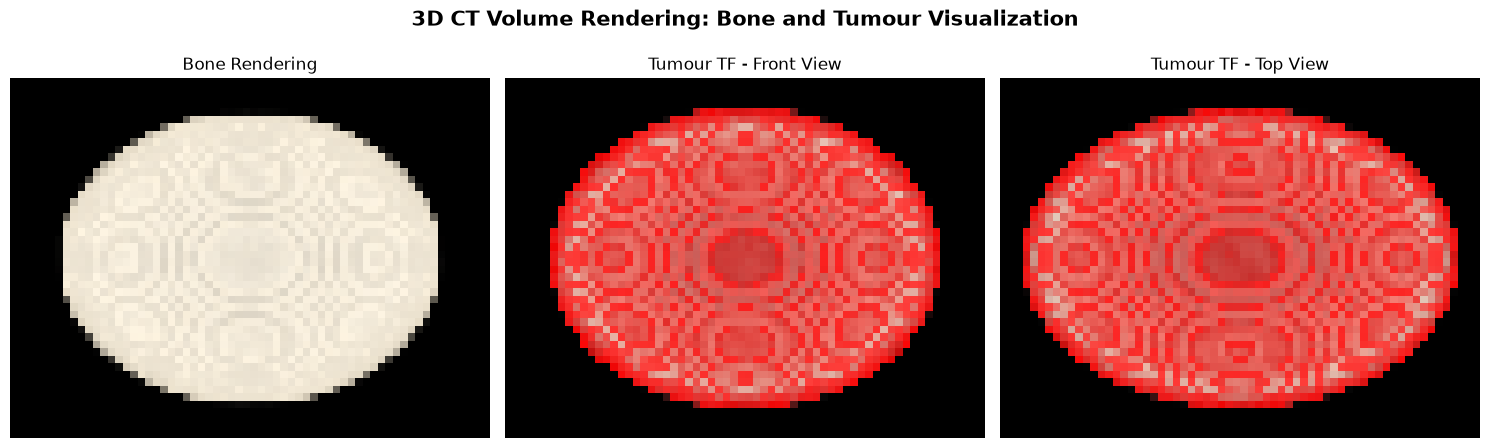

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Existing bone transfer function
bone_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (200, (0, 0, 0), 0),
    (400, (1, 0.95, 0.85), 0.3),
    (1500, (1, 1, 1), 0.6)
])

# TODO 2: Custom transfer function to highlight tumour
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (-100, (0, 0, 0), 0),
    (20, (0.2, 0.2, 0.2), 0.02),
    (40, (0.8, 0.2, 0.2), 0.15),
    (80, (1, 0, 0), 0.65),
    (150, (1, 0.1, 0.1), 0.85),
    (200, (0.8, 0, 0), 0.4),
    (400, (1, 0.95, 0.85), 0.08),
    (1500, (1, 1, 1), 0.1)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1: Bone rendering
bone_render = render_volume(volume, bone_tf, view="front")

axes[0].imshow(bone_render)
axes[0].set_title("Bone Rendering")
axes[0].axis("off")


# TODO 3: Tumour transfer function - Front view
tumour_front = render_volume(volume, tumour_tf, view="front")

axes[1].imshow(tumour_front)
axes[1].set_title("Tumour TF - Front View")
axes[1].axis("off")


# TODO 3: Tumour transfer function - Top view
tumour_top = render_volume(volume, tumour_tf, view="top")

axes[2].imshow(tumour_top)
axes[2].set_title("Tumour TF - Top View")
axes[2].axis("off")


# TODO 4: Main title
fig.suptitle(
    "3D CT Volume Rendering: Bone and Tumour Visualization",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_The red rim appears because different tissues can have overlapping intensity values, so the software mistakes some normal tissue for tumour. We can use **segmentation** to separate the tumour from the surrounding tissues and remove the rim. A transfer function alone cannot fix this because it only uses intensity values and cannot always tell which tissue is which.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_The CT scan shows a lesion in the brain, with an estimated volume between [minimum] and [maximum] mm³ based on different threshold values. I would start the meeting with the segmentation overlay because it clearly shows where the lesion is and helps us measure its size. It also makes it easier to compare the tumour with the surrounding brain tissue. The 3-D render is useful, but some parts of the lesion might be hidden by other tissues due to occlusion. Also, overlapping intensity values can make normal tissue look like part of the tumour, so we should not depend only on the 3-D view.